In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
import random

# function to control randomness
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

In [ ]:
# function to select behavior dynamically
def make_activation(name: str) -> nn.Module:
    activations = {
        "sigmoid": nn.Sigmoid,
        "tanh": nn.Tanh,
        "relu": nn.ReLU,
    }
    if name not in activations:
        raise ValueError(f"Unknown activation: {name}")
    return activations[name]()

In [ ]:
# function to controll initial weights
def initialize_linear_layers(model: nn.Module, scheme: str, activation: str) -> None:
    for module in model.modules():
        if not isinstance(module, nn.Linear):
            continue

        if scheme == "xavier":
            nn.init.xavier_uniform_(module.weight)
        elif scheme == "he":
            # Kaiming/He initialization is primarily intended for ReLU-like activations.
            nonlinearity = "relu" if activation == "relu" else "leaky_relu"
            nn.init.kaiming_uniform_(module.weight, nonlinearity=nonlinearity)
        elif scheme == "default":
            # Keep PyTorch's default Linear initialization for a baseline.
            pass
        else:
            raise ValueError(f"Unknown initialization: {scheme}")

        if module.bias is not None and scheme != "default":
            nn.init.zeros_(module.bias)

In [ ]:
# constructing a configurable neural network
class MLP(nn.Module):
    def __init__(
        self,
        input_dim: int = 20,
        width: int = 64,
        depth: int = 8,
        activation: str = "relu",
        init: str = "xavier",
    ):
        super().__init__()
        layers = []
        in_features = input_dim

        for _ in range(depth):
            layers.append(nn.Linear(in_features, width))
            layers.append(make_activation(activation))
            in_features = width

        layers.append(nn.Linear(in_features, 1))  # logit output
        self.network = nn.Sequential(*layers)
        initialize_linear_layers(self, init, activation)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.network(x)

In [ ]:
x = torch.randn(128, 20, device=DEVICE)
y = torch.randint(0, 2, (128, 1), dtype=torch.float32, device=DEVICE)

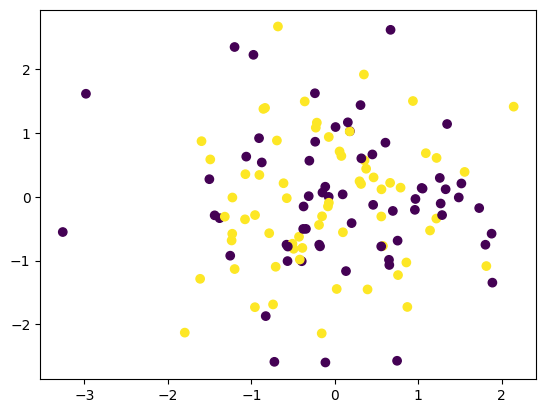

In [ ]:
plt.scatter(x.cpu()[:, 0], x.cpu()[:, 1], c=y.cpu())

In [ ]:
# the core of the research experiment
def measure_gradients(
    depth: int,
    activation: str,
    init: str,
    seed: int,
    batch_size: int = 128,
    input_dim: int = 20,
    width: int = 64,
) -> list[dict]:
    set_seed(seed)
    model = MLP(input_dim, width, depth, activation, init).to(DEVICE)
    x = torch.randn(batch_size, input_dim, device=DEVICE)
    # Fixed random binary targets make a reproducible diagnostic objective.
    y = torch.randint(0, 2, (batch_size, 1), dtype=torch.float32, device=DEVICE)

    model.zero_grad(set_to_none=True)
    logits = model(x)
    loss = nn.BCEWithLogitsLoss()(logits, y)
    loss.backward()

    rows = []
    linear_index = 0
    for module in model.modules():
        if isinstance(module, nn.Linear):
            grad = module.weight.grad
            if grad is None:
                grad_norm = float("nan")
                grad_rms = float("nan")
            else:
                grad_norm = grad.detach().norm(2).item()
                grad_rms = grad.detach().pow(2).mean().sqrt().item()
            rows.append({
                "seed": seed,
                "depth": depth,
                "activation": activation,
                "init": init,
                "layer_index": linear_index,
                "is_output_layer": linear_index == depth,
                "weight_grad_l2": grad_norm,
                "weight_grad_rms": grad_rms,
                "loss": loss.item(),
            })
            linear_index += 1
    return rows

In [ ]:
# designing the experimental comparisons
all_rows = []
seeds = [11, 23, 37]

# Study A: activation ablation; same depth and initialization.
for activation in ["sigmoid", "tanh", "relu"]:
    for seed in seeds:
        all_rows.extend(measure_gradients(
            depth=8, activation=activation, init="xavier", seed=seed
        ))

# Study B: depth scaling; same activation and initialization.
for depth in [4, 8, 16, 32]:
    for seed in seeds:
        all_rows.extend(measure_gradients(
            depth=depth, activation="relu", init="he", seed=seed
        ))

# Study C: initialization ablation for ReLU; compare Xavier and He.
for init in ["xavier", "he"]:
    for seed in seeds:
        all_rows.extend(measure_gradients(
            depth=8, activation="relu", init=init, seed=seed
        ))

df = pd.DataFrame(all_rows)
df.to_csv("results/gradient_measurements.csv", index=False)

## Study A — Activation Function Ablation

**Objective:** Investigate how activation functions affect gradient flow while keeping network depth (8 layers) and Xavier initialization fixed.

- **Compared:** Sigmoid, Tanh, and ReLU.
- **Output:** Per-layer weight gradient L2 norm, RMS norm, and loss for each seed.
- **Findings:** Sigmoid shows very small gradients at layer 0 (approximately `2.16 × 10⁻⁶`), indicating a strong vanishing-gradient pattern. Tanh and ReLU show larger gradients in the same layer.
- **Conclusion:** Activation function choice substantially affects gradient magnitudes in this experiment.

## Study B — Network Depth Scaling

**Objective:** Examine how increasing network depth affects gradient flow.

- **Compared:** Depths of 4, 8, 16, and 32, using ReLU activation and He initialization.
- **Output:** Per-layer gradient norms and loss for each depth and seed.
- **Findings:** The mean gradient norm at layer 0 decreases from approximately `0.254` at depth 4 to `0.112` at depth 32.
- **Conclusion:** Network depth changes gradient behavior, although the trend may differ across layers.

## Study C — Weight Initialization Ablation

**Objective:** Investigate how initialization affects gradient flow while keeping ReLU activation and network depth (8 layers) fixed.

- **Compared:** Xavier and He initialization.
- **Output:** Per-layer gradient norms and loss for each initialization and seed.
- **Findings:** He initialization produces a larger mean gradient norm at layer 0 (`0.228`) than Xavier initialization (`0.0174`).
- **Conclusion:** Weight initialization strongly influences gradient magnitudes, even when activation function and network depth remain fixed.

## Important Note

These results come from a single backward pass using synthetic random data. They demonstrate gradient-flow behavior under the tested conditions but do not establish training performance on a real dataset.

In [ ]:
df.head()

,seed,depth,activation,init,layer_index,is_output_layer,weight_grad_l2,weight_grad_rms,loss
0,11,8,sigmoid,xavier,0,False,0.000001,3.904401e-08,0.699896
1,11,8,sigmoid,xavier,1,False,0.000016,2.441843e-07,0.699896
2,11,8,sigmoid,xavier,2,False,0.000079,1.231846e-06,0.699896
3,11,8,sigmoid,xavier,3,False,0.000353,5.518305e-06,0.699896
4,11,8,sigmoid,xavier,4,False,0.001623,2.536455e-05,0.699896


In [ ]:
# Summarize across seeds for each experimental condition and layer.
summary = (
    df.groupby(
        ["depth", "activation", "init", "layer_index", "is_output_layer"],
        as_index=False
    )
    .agg(
        mean_grad_l2=("weight_grad_l2", "mean"),
        std_grad_l2=("weight_grad_l2", "std"),
        mean_grad_rms=("weight_grad_rms", "mean"),
        mean_loss=("loss", "mean"),
    )
)
summary.to_csv("result/run_summary.csv", index=False)

## Summary — Aggregating Results Across Seeds

**Objective:** Summarize gradient measurements across multiple random seeds for each experimental condition and layer.

- **Grouping:** Groups results by network depth, activation function, initialization method, layer index, and whether the layer is the output layer.
- **Calculations:**
  - `mean_grad_l2`: Average L2 gradient norm across seeds.
  - `std_grad_l2`: Standard deviation of L2 gradient norms, indicating variation across seeds.
  - `mean_grad_rms`: Average RMS gradient norm across seeds.
  - `mean_loss`: Average loss across seeds.
- **Output:** Saves the aggregated results to `run_summary.csv`.

### What the Output Shows

The CSV contains **91 rows and 9 columns**. Each row represents a specific experimental configuration and layer, summarized across the three seeds.

- **Mean gradient values** show the typical gradient magnitude for each layer.
- **Standard deviation** indicates how much the L2 gradient norm varies across different seeds.
- **Mean loss** provides an average loss value for each configuration.

### Conclusion

This summary makes it easier to compare gradient behavior across layers and experimental conditions without examining every individual seed measurement. It also helps identify layers with unusually small gradients and configurations with greater variation.

**Note:** The code calculates standard deviation only for `weight_grad_l2`, not for RMS gradients or loss. Since loss is measured for the whole model, its summarized value is repeated across the layer rows belonging to the same configuration.

In [ ]:
summary.head()

,depth,activation,init,layer_index,is_output_layer,mean_grad_l2,std_grad_l2,mean_grad_rms,mean_loss
0,4,relu,he,0,False,0.254211,0.102223,0.007105,0.876605
1,4,relu,he,1,False,0.723146,0.547980,0.011299,0.876605
2,4,relu,he,2,False,0.834500,0.617898,0.013039,0.876605
3,4,relu,he,3,False,1.037217,0.796685,0.016207,0.876605
4,4,relu,he,4,True,1.071911,0.857816,0.133989,0.876605


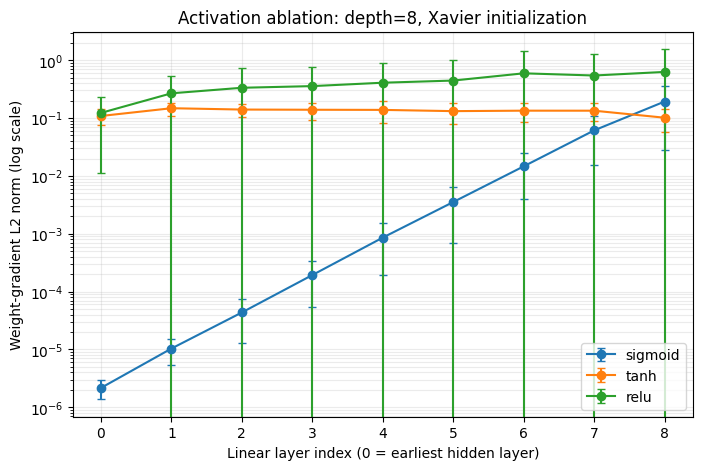

In [ ]:
# visualizing activation effects
subset = df[df["depth"] == 8]
fig, ax = plt.subplots(figsize=(8, 5))

for activation in ["sigmoid", "tanh", "relu"]:
    part = subset[subset["activation"] == activation]
    grouped = part.groupby("layer_index")["weight_grad_l2"].agg(["mean", "std"])
    ax.errorbar(
        grouped.index, grouped["mean"],
        yerr=grouped["std"].fillna(0),
        marker="o", capsize=3, label=activation
    )

ax.set_yscale("log")
ax.set_xlabel("Linear layer index (0 = earliest hidden layer)")
ax.set_ylabel("Weight-gradient L2 norm (log scale)")
ax.set_title("Activation ablation: depth=8, Xavier initialization")
ax.grid(True, which="both", alpha=0.25)
ax.legend()
plt.show()

fig.tight_layout()
fig.savefig("results/figures/activation_ablation.png", dpi=160)
plt.close(fig)

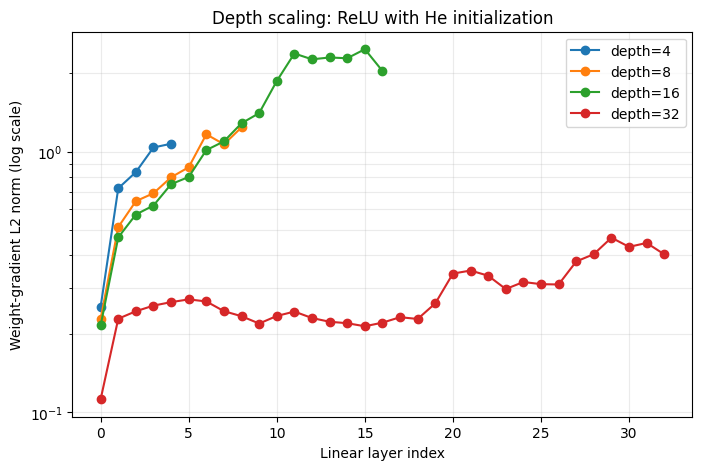

In [ ]:
subset = df[(df["activation"] == "relu") & (df["init"] == "he")]
fig, ax = plt.subplots(figsize=(8, 5))

for depth in [4, 8, 16, 32]:
    part = subset[subset["depth"] == depth]
    grouped = part.groupby("layer_index")["weight_grad_l2"].agg(["mean", "std"])
    ax.plot(grouped.index, grouped["mean"], marker="o", label=f"depth={depth}")

ax.set_yscale("log")
ax.set_xlabel("Linear layer index")
ax.set_ylabel("Weight-gradient L2 norm (log scale)")
ax.set_title("Depth scaling: ReLU with He initialization")
ax.grid(True, which="both", alpha=0.25)
ax.legend()
plt.show()

fig.tight_layout()
fig.savefig("results/figures/depth_scaling.png", dpi=160)
plt.close(fig)

## Final Conclusion

This study investigates how activation functions, network depth, and weight initialization influence gradient flow in deep neural networks.

- **Study A — Activation Ablation:** Sigmoid exhibits vanishing gradients in earlier layers, while Tanh and ReLU maintain substantially larger gradient magnitudes.
- **Study B — Depth Scaling:** Gradient behavior varies with network depth. The 32-layer network shows smaller gradient norms than shallower networks in this experiment, although the trend differs across layers.
- **Study C — Initialization Ablation:** He initialization produces larger gradient magnitudes than Xavier initialization for the tested ReLU network.

### Graph Interpretation

1. **Activation Ablation Graph:** The logarithmic y-axis highlights the extremely small gradients for Sigmoid compared with Tanh and ReLU. The large error bars for ReLU indicate substantial variation across seeds.
2. **Depth Scaling Graph:** Gradient norms differ across network depths, with the 32-layer network showing lower magnitudes than the shallower networks. However, the plotted profiles should be interpreted cautiously because the x-axis uses forward layer indices, and the networks have different numbers of layers.

### Overall Finding

Activation functions and initialization methods strongly influence gradient magnitudes, while increasing network depth changes how gradients propagate through layers. These findings support the importance of selecting suitable activations and initialization strategies when designing deep neural networks.

**Limitation:** These experiments measure gradients from a single backward pass on synthetic data. They provide an initial diagnostic of gradient flow, not proof of improved training performance or generalization. Further experiments using controlled comparisons and real datasets are needed to validate the findings.